# Move-IIT-HPE — Experiment A: Accuracy from predictions and 2D GT

**Inputs:** the 708 completed prediction CSVs and the 59 matching **2D ground-truth projection CSVs** (`*_joint_projections.csv`). There is **no reading of raw Vicon data, no 3D marker processing and no 3D-to-2D projection step** in this notebook. The supplied 2D GT files are derived from the dataset's motion-capture annotations; the origin of the annotations does not change what the notebook reads.

**Methods:** MoveEnet-only vs MoveEnetOFK (ROI 35, flow 200 Hz, output 200 Hz); 6 neural inference frequencies. Separate editable PCK@0.2, MPJPE, and per-joint figures, plus paired accuracy tables.

**Compatibility:** the default metric settings match the prior Experiment A notebook's finite-**row** evaluation, interpolation of GT onto actual prediction timestamps, and torso reference joints (1, 5). The mapping from projection labels into the 13 MoveEnet joint indices remains a **working assumption**, not a verified anatomical equivalence.

## Evaluation protocol — same metrics as earlier Experiment A

- Read existing inference CSVs and 2D GT (`*_joint_projections.csv`); **no model execution**.
- Interpolate GT to each actual prediction timestamp, using the first/last GT positions at the endpoints (the previous ExpA convention). Never interpolate or synthesize predictions.
- Evaluate full rows where **all 13 predicted and GT joints are finite**, using the same valid timestamps for both methods.
- MPJPE: mean Euclidean distance in pixels. PCK@0.2 and PCK@0.4: threshold relative to GT shoulder-right (index 1) to hip-left (index 5), as in the existing ExpA/ExpFinal pipeline.
- Aggregate by joint-observation counts, so longer recordings contribute proportionally. Bootstrap 95% CI across recordings for visualization.
- **Optional** out-of-frame exclusion can be enabled in configuration, but defaults to **off**, consistent with the earlier ExpA metric protocol. The 2678 out-of-frame annotations are reported, not silently filtered.

**Assumptions to validate for paper:** 2D GT joint names/order correspond to MoveEnet's 13 anatomical joints; ground-truth timestamp offset is set to 0 s. The script detects and shows each unique ground-truth column layout, rather than requiring exact hard-coded marker labels.

## 1. Paths, parameters and plot settings

In [9]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# -------- Change only these parameters, if needed --------
BASE = Path('/data/MoveEnet_OFK_results/Final_ROI_Gain1/Accuracy/moveiit/ExpA')
OUT = BASE / 'analysis_2d_gt_expa_protocol'
NETWORK_PERIODS = ('0.01', '0.02', '0.05', '0.1', '0.2', '0.5')
EXPECTED_SEQUENCES = 59
GT_TIME_OFFSET_S = 0.0    # GT sampled at prediction time + offset
FILTER_OUT_OF_FRAME_GT = False  # True changes the earlier ExpA metric protocol
GT_INTERPOLATION = 'endpoint_hold'  # same as original ExpA
BOOTSTRAP_ITERATIONS = 1000
RANDOM_SEED = 12345
SAVE_FIGURES = True
FIGURE_FORMATS = ('svg', 'pdf', 'png')
DPI = 300

# Paper figure appearance: independently adjustable
FIGSIZE = (7.5, 4.8)
FONT_SIZE = 12
LABEL_SIZE = 13
TICK_SIZE = 11
LEGEND_SIZE = 11
TITLE_SIZE = 13
LINE_WIDTH = 2.2
MARKER_SIZE = 7
SHOW_CI = True

# Stable style across both figures
COLORS = {'moveenet_only': '#375A9E', 'moveenet_ofk': '#D47A3C'}
MARKERS = {'moveenet_only': 's', 'moveenet_ofk': 'o'}
LABELS = {'moveenet_only': 'MoveEnet-only',
          'moveenet_ofk': 'MoveEnetOFK (ROI 35, flow 200 Hz)'}
METHODS = ('moveenet_only', 'moveenet_ofk')

plt.rcParams.update({
    'font.size': FONT_SIZE,
    'axes.labelsize': LABEL_SIZE,
    'axes.titlesize': TITLE_SIZE,
    'xtick.labelsize': TICK_SIZE,
    'ytick.labelsize': TICK_SIZE,
    'legend.fontsize': LEGEND_SIZE,
    'svg.fonttype': 'none',  # text is editable in vector SVG viewers
    'pdf.fonttype': 42,
})

print('Input:', BASE)
print('Output:', OUT)
print('Network frequencies (Hz):', sorted(1 / float(x) for x in NETWORK_PERIODS))
print('GT source: 2D joint projections (CSV), not raw Vicon')
print('Filter out-of-frame GT:', FILTER_OUT_OF_FRAME_GT)

Input: /data/MoveEnet_OFK_results/Final_ROI_Gain1/Accuracy/moveiit/ExpA
Output: /data/MoveEnet_OFK_results/Final_ROI_Gain1/Accuracy/moveiit/ExpA/analysis_2d_gt_expa_protocol
Network frequencies (Hz): [2.0, 5.0, 10.0, 20.0, 50.0, 100.0]
GT source: 2D joint projections (CSV), not raw Vicon
Filter out-of-frame GT: False


## 2. Load and verify experiment manifest

In [10]:
def require(condition, message):
    if not condition:
        raise RuntimeError(message)

manifest_path = BASE / 'manifest.csv'
require(manifest_path.is_file(), f'Missing manifest: {manifest_path}')
require((BASE / 'config.txt').is_file(), f'Missing runner config: {BASE / "config.txt"}')
config_text = (BASE / 'config.txt').read_text()
require('roi=35\n' in config_text and 'moveiit=true' in config_text,
        'Unexpected configuration: expected ROI=35 and moveiit=true')

manifest = pd.read_csv(manifest_path, dtype=str)
require({'subject', 'sequence', 'events', 'ground_truth'} <= set(manifest.columns),
        'Unexpected manifest columns')
require(len(manifest) == EXPECTED_SEQUENCES,
        f'Expected {EXPECTED_SEQUENCES} recordings, found {len(manifest)}')
require(not manifest.duplicated(['subject', 'sequence']).any(),
        'Duplicate subject/sequence pairs in manifest')

expected_runs = len(manifest) * len(NETWORK_PERIODS) * len(METHODS)
print(f'Paired sequences: {len(manifest)} | Expected prediction CSVs: {expected_runs}')
display(manifest[['subject', 'sequence']].groupby('subject').agg(
    sequences=('sequence', 'count')))
display(manifest[['subject', 'sequence', 'ground_truth']].head(5))

Paired sequences: 59 | Expected prediction CSVs: 708


,sequences
subject,
luna,26
simon,33


,subject,sequence,ground_truth
0,luna,box_f1,/data/move-iit-it_testing/GT/P1_luna/box_f1_jo...
1,luna,box_s1,/data/move-iit-it_testing/GT/P1_luna/box_s1_jo...
2,luna,drum_f1,/data/move-iit-it_testing/GT/P1_luna/drum_f1_j...
3,luna,drum_s1,/data/move-iit-it_testing/GT/P1_luna/drum_s1_j...
4,luna,march_f1,/data/move-iit-it_testing/GT/P1_luna/march_f1_...


## 3. Read the 2D GT and prediction CSVs

The 2D ground-truth CSV headers may differ between recordings. Only their required *structure* (timestamp + 13 x/y pairs) is assumed; the notebook prints the detected layout.

In [11]:
# Skeleton order used by MoveEnet's inference CSVs.
JOINT_NAMES = (
    'Head', 'Right shoulder', 'Left shoulder', 'Right elbow', 'Left elbow',
    'Left hip', 'Right hip', 'Right wrist', 'Left wrist',
    'Right knee', 'Left knee', 'Right ankle', 'Left ankle'
)
# PROVISIONAL mapping from dataset GT projection order to MoveEnet's indices.
# Identical to the previous one-sequence comparison; NOT a Vicon computation.
PROJECTION_TO_moveenet = np.array([0, 1, 2, 3, 4, 8, 7, 5, 6, 9, 10, 11, 12])
PRED_COLS = ['timestamp', 'latency'] + [
    f'joint{j}_{axis}' for j in range(13) for axis in 'xy'
]
seen_gt_schemas = {}


def load_gt(path):
    """Read the *already projected 2D GT*, never raw Vicon/3D data."""
    df = pd.read_csv(path, encoding='utf-8-sig')
    df.columns = [str(x).strip() for x in df.columns]
    # Some CSV exporters prepend an unnamed saved DataFrame index.
    df = df.loc[:, ~df.columns.str.match(r'^Unnamed: \d+$')]
    time_col = 'event_timestamp' if 'event_timestamp' in df.columns else (
        'timestamp' if 'timestamp' in df.columns else df.columns[0])
    coord_cols = [c for c in df.columns if c != time_col]
    require(len(coord_cols) == 26,
            f'GT must contain 13 (x,y) pairs; {path} has {len(coord_cols)} '
            f'coordinate columns: {coord_cols}')
    # Check consistent pairs when labels have _x/_y suffixes. Do not require
    # particular marker names (Luna and Simon may have different headers).
    for j in range(13):
        cx, cy = coord_cols[2*j:2*j+2]
        if cx.lower().endswith('_x') and cy.lower().endswith('_y'):
            require(cx[:-2].lower() == cy[:-2].lower(),
                    f'GT (x,y) columns are mispaired in {path}: {cx}, {cy}')
    schema = tuple(coord_cols)
    seen_gt_schemas.setdefault(schema, []).append(path)
    times = pd.to_numeric(df[time_col], errors='raise').to_numpy(dtype=float)
    xy = df[coord_cols].apply(pd.to_numeric, errors='raise').to_numpy(dtype=float)
    require(len(times) >= 2 and np.isfinite(times).all()
            and np.all(np.diff(times) > 0), f'Invalid GT timestamps: {path}')
    # If the GT is already joint0_x..joint12_y, it is in MoveEnet order.
    native_order = all(coord_cols[2*j:2*j+2] == [f'joint{j}_x', f'joint{j}_y']
                       for j in range(13))
    mapping = np.arange(13) if native_order else PROJECTION_TO_moveenet
    coords = xy.reshape(-1, 13, 2)[:, mapping, :]
    finite = np.isfinite(coords).all(axis=2)
    inside = (finite & (coords[..., 0] >= 0) & (coords[..., 0] < 1280)
              & (coords[..., 1] >= 0) & (coords[..., 1] < 720))
    return times, coords, inside, finite


def load_prediction(path):
    require(path.is_file(), f'Missing prediction: {path}')
    df = pd.read_csv(path)
    require(list(df.columns[:28]) == PRED_COLS, f'Unexpected prediction columns: {path}')
    times = df.timestamp.to_numpy(dtype=float)
    coords = df[PRED_COLS[2:]].to_numpy(dtype=float).reshape(-1, 13, 2)
    require(len(times) >= 2 and np.isfinite(times).all()
            and np.all(np.diff(times) > 0), f'Invalid prediction times: {path}')
    return times, coords


def interpolate_gt(t_pred, t_gt, xy_gt):
    """GT-only linear interpolation with endpoint hold (existing ExpA)."""
    query = t_pred + GT_TIME_OFFSET_S
    result = np.empty((len(query), 13, 2), dtype=float)
    for j in range(13):
        for axis in range(2):
            result[:, j, axis] = np.interp(query, t_gt, xy_gt[:, j, axis])
    return result


## 4. Evaluate all predictions against the 2D GT

This reads the **708 existing inference CSVs** and the matching 2D GT CSVs. No model is run. Evaluations use the same prediction timestamps for both methods.

In [12]:
sample_rows, joint_rows, gt_quality_rows = [], [], []

for i, rec in enumerate(manifest.itertuples(index=False), start=1):
    subject, sequence = rec.subject, rec.sequence
    gt_times, gt_coords, gt_inside, gt_finite = load_gt(Path(rec.ground_truth))
    gt_quality_rows.append({
        'subject': subject, 'sequence': sequence,
        'gt_rows': len(gt_times), 'gt_start_s': gt_times[0], 'gt_end_s': gt_times[-1],
        'gt_nonfinite_annotations': int((~gt_finite).sum()),
        'gt_out_of_frame_annotations': int((gt_finite & ~gt_inside).sum()),
    })
    stem = f'{subject}__{sequence}__atis-s'
    for period in NETWORK_PERIODS:
        safe = period.replace('.', 'p')
        raw_dir = BASE / 'raw' / 'fp_0p005' / f'np_{safe}'
        pred = {}
        for method in METHODS:
            name = f'{stem}_{method}_np_{safe}_fp_0p005'
            log_path = BASE / 'logs' / f'{name}.log'
            csv_path = raw_dir / f'{name}.csv'
            require(log_path.is_file() and 'Finished processing event file.'
                    in log_path.read_text(errors='replace'),
                    f'Incomplete run: {log_path}')
            pred[method] = load_prediction(csv_path)

        t = pred[METHODS[0]][0]
        require(all(np.array_equal(t, pred[m][0]) for m in METHODS[1:]),
                f'Mismatched prediction timestamps: {subject}/{sequence}/{period}')
        gt_at_t = interpolate_gt(t, gt_times, gt_coords)
        valid_rows = np.isfinite(gt_at_t).all(axis=(1, 2)) & np.isfinite(t)
        for method in METHODS:
            valid_rows &= np.isfinite(pred[method][1]).all(axis=(1, 2))
        if FILTER_OUT_OF_FRAME_GT:
            valid_rows &= (gt_at_t[..., 0] >= 0).all(axis=1)
            valid_rows &= (gt_at_t[..., 0] < 1280).all(axis=1)
            valid_rows &= (gt_at_t[..., 1] >= 0).all(axis=1)
            valid_rows &= (gt_at_t[..., 1] < 720).all(axis=1)
        require(valid_rows.any(), f'No valid rows: {subject}/{sequence}/{period}')
        g = gt_at_t[valid_rows]
        torso = np.linalg.norm(g[:, 1] - g[:, 5], axis=1)
        torso = np.maximum(torso, 1e-6)
        for method in METHODS:
            p = pred[method][1][valid_rows]
            error = np.linalg.norm(p - g, axis=2)
            correct02 = error <= .2 * torso[:, None]
            correct04 = error <= .4 * torso[:, None]
            n_points = int(error.size)
            sample_rows.append({
                'subject': subject, 'sequence': sequence,
                'sample_id': f'{subject}/{sequence}', 'method': method,
                'net_period_s': float(period), 'net_hz': 1. / float(period),
                'roi': 35, 'flow_hz': 200, 'output_hz': 200,
                'output_rows': len(t), 'valid_rows': int(valid_rows.sum()),
                'valid_joints': n_points, 'valid_pck_joints': n_points,
                'sum_error_px': float(error.sum()),
                'correct_pck02': int(correct02.sum()),
                'correct_pck04': int(correct04.sum()),
                'mpjpe_px': float(error.mean()),
                'pck02_percent': float(100 * correct02.mean()),
                'pck04_percent': float(100 * correct04.mean()),
            })
            for j, label in enumerate(JOINT_NAMES):
                joint_rows.append({
                    'subject': subject, 'sequence': sequence, 'method': method,
                    'net_hz': 1. / float(period), 'joint': label,
                    'valid_joints': int(error.shape[0]),
                    'valid_pck_joints': int(error.shape[0]),
                    'sum_error_px': float(error[:, j].sum()),
                    'correct_pck02': int(correct02[:, j].sum()),
                })
    print(f'[{i:02d}/{len(manifest)}] {subject}/{sequence}: OK')

samples = pd.DataFrame(sample_rows)
joints = pd.DataFrame(joint_rows)
gt_quality = pd.DataFrame(gt_quality_rows)
require(len(samples) == expected_runs, 'Incomplete evaluation')
print(f'Analyzed {len(samples)} runs. No inference was executed.')
print('2D GT column layouts detected:', len(seen_gt_schemas))
for k, (schema, paths) in enumerate(seen_gt_schemas.items(), 1):
    print(f'  Layout {k}: {len(paths)} recordings; e.g. {paths[0].name}')
    print('  Names:', ', '.join(schema[0::2]))
print('Out-of-frame 2D GT annotations (reported; filter is %s): %d' % (
    'ON' if FILTER_OUT_OF_FRAME_GT else 'OFF',
    gt_quality.gt_out_of_frame_annotations.sum()))

[01/59] luna/box_f1: OK
[02/59] luna/box_s1: OK
[03/59] luna/drum_f1: OK
[04/59] luna/drum_s1: OK
[05/59] luna/march_f1: OK
[06/59] luna/march_s1: OK
[07/59] luna/mix_f1: OK
[08/59] luna/mix_s1: OK
[09/59] luna/pour_f1: OK
[10/59] luna/pour_s1: OK
[11/59] luna/side_f1: OK
[12/59] luna/side_s1: OK
[13/59] luna/sit-drum_f1: OK
[14/59] luna/sit-drum_s1: OK
[15/59] luna/sit-mix_f1: OK
[16/59] luna/sit-mix_s1: OK
[17/59] luna/sit-pour_f1: OK
[18/59] luna/sit-pour_s1: OK
[19/59] luna/sit_f1: OK
[20/59] luna/sit_s1: OK
[21/59] luna/skater_f1: OK
[22/59] luna/skater_s1: OK
[23/59] luna/tennis_f1: OK
[24/59] luna/tennis_s1: OK
[25/59] luna/walk_f1: OK
[26/59] luna/walk_s1: OK
[27/59] simon/box_f1: OK
[28/59] simon/box_s1: OK
[29/59] simon/drum_f1: OK
[30/59] simon/drum_s1: OK
[31/59] simon/jump_f2: OK
[32/59] simon/jump_s2: OK
[33/59] simon/march_f1: OK
[34/59] simon/march_s1: OK
[35/59] simon/mix_f1: OK
[36/59] simon/mix_s1: OK
[37/59] simon/monkey_f1: OK
[38/59] simon/monkey_s1: OK
[39/59] si

## 5. Pool measurements and compute 95% sequence-bootstrap confidence intervals

In [13]:
rng = np.random.default_rng(RANDOM_SEED)
summary_rows = []
for (period, method), group in samples.groupby(['net_period_s', 'method'], sort=True):
    error_sum = group.sum_error_px.sum()
    joint_n = group.valid_joints.sum()
    pck_n = group.valid_pck_joints.sum()
    result = {
        'method': method, 'net_period_s': period, 'net_hz': 1. / period,
        'n_sequences': len(group), 'valid_joints': int(joint_n),
        'valid_pck_joints': int(pck_n),
        'mpjpe_px': float(error_sum / joint_n),
        'pck02_percent': float(100 * group.correct_pck02.sum() / pck_n),
        'pck04_percent': float(100 * group.correct_pck04.sum() / pck_n),
        'macro_mpjpe_px': float(group.mpjpe_px.mean()),
        'macro_pck02_percent': float(group.pck02_percent.mean()),
    }
    ids = rng.integers(0, len(group), size=(BOOTSTRAP_ITERATIONS, len(group)))
    error_boot = group.sum_error_px.to_numpy()[ids].sum(axis=1)
    joint_boot = group.valid_joints.to_numpy()[ids].sum(axis=1)
    pck_boot = group.correct_pck02.to_numpy()[ids].sum(axis=1)
    pck_n_boot = group.valid_pck_joints.to_numpy()[ids].sum(axis=1)
    result['mpjpe_px_ci_low'], result['mpjpe_px_ci_high'] = np.quantile(
        error_boot / joint_boot, [.025, .975])
    result['pck02_percent_ci_low'], result['pck02_percent_ci_high'] = np.quantile(
        100 * pck_boot / pck_n_boot, [.025, .975])
    summary_rows.append(result)
summary = pd.DataFrame(summary_rows).sort_values(['net_hz', 'method']).reset_index(drop=True)

display(summary[['net_hz', 'method', 'n_sequences', 'mpjpe_px', 'pck02_percent',
                 'valid_joints', 'valid_pck_joints']].round(3))

,net_hz,method,n_sequences,mpjpe_px,pck02_percent,valid_joints,valid_pck_joints
0,2.0,moveenet_ofk,59,63.966,33.475,1577745,1577745
1,2.0,moveenet_only,59,68.904,29.848,1577745,1577745
2,5.0,moveenet_ofk,59,60.894,35.770,1577745,1577745
3,5.0,moveenet_only,59,63.849,34.258,1577745,1577745
4,10.0,moveenet_ofk,59,60.410,36.557,1577745,1577745
5,10.0,moveenet_only,59,63.024,35.876,1577745,1577745
6,20.0,moveenet_ofk,59,59.607,37.103,1577745,1577745
7,20.0,moveenet_only,59,62.395,36.561,1577745,1577745
8,50.0,moveenet_ofk,59,59.244,37.289,1577745,1577745
9,50.0,moveenet_only,59,62.266,36.647,1577745,1577745


## 6. Paired improvements — OFK relative to MoveEnet-only

In [14]:
delta_rows = []
for period in sorted(samples.net_period_s.unique()):
    grp = samples[samples.net_period_s == period]
    ofk = grp[grp.method == 'moveenet_ofk'].set_index('sample_id').sort_index()
    net = grp[grp.method == 'moveenet_only'].set_index('sample_id').sort_index()
    require(ofk.index.equals(net.index), 'Unpaired sample identifiers')
    require(np.array_equal(ofk.valid_joints, net.valid_joints) and
            np.array_equal(ofk.valid_pck_joints, net.valid_pck_joints),
            'GT masks differ between methods')
    delta_mp = net.mpjpe_px.to_numpy() - ofk.mpjpe_px.to_numpy()
    delta_pck = ofk.pck02_percent.to_numpy() - net.pck02_percent.to_numpy()
    delta_rows.append({
        'net_period_s': period, 'net_hz': 1. / period,
        'n_sequences': len(ofk),
        'pooled_mpjpe_reduction_px': (
            net.sum_error_px.sum() / net.valid_joints.sum() -
            ofk.sum_error_px.sum() / ofk.valid_joints.sum()),
        'pooled_pck_improvement_pp': 100 * (
            ofk.correct_pck02.sum() / ofk.valid_pck_joints.sum() -
            net.correct_pck02.sum() / net.valid_pck_joints.sum()),
        'mean_sequence_mpjpe_reduction_px': delta_mp.mean(),
        'mean_sequence_pck_improvement_pp': delta_pck.mean(),
        'n_sequences_better_mpjpe': int((delta_mp > 0).sum()),
        'n_sequences_better_pck02': int((delta_pck > 0).sum()),
    })
deltas = pd.DataFrame(delta_rows).sort_values('net_hz').reset_index(drop=True)
display(deltas[['net_hz', 'pooled_mpjpe_reduction_px',
                'pooled_pck_improvement_pp', 'n_sequences_better_mpjpe',
                'n_sequences_better_pck02']].round(3))

,net_hz,pooled_mpjpe_reduction_px,pooled_pck_improvement_pp,n_sequences_better_mpjpe,n_sequences_better_pck02
0,2.0,4.938,3.627,59,57
1,5.0,2.955,1.512,59,54
2,10.0,2.614,0.681,59,43
3,20.0,2.788,0.541,59,34
4,50.0,3.022,0.642,59,36
5,100.0,3.025,0.679,59,39


## 7. Export tables and protocol (without rerunning inference)

In [15]:
OUT.mkdir(parents=True, exist_ok=True)
samples.to_csv(OUT / 'accuracy_by_sample.csv', index=False)
summary.to_csv(OUT / 'accuracy_summary.csv', index=False)
deltas.to_csv(OUT / 'paired_improvements.csv', index=False)
joints.to_csv(OUT / 'accuracy_by_joint_by_sample.csv', index=False)
gt_quality.to_csv(OUT / 'ground_truth_quality.csv', index=False)
protocol = {
    'dataset': 'move-iit-hpe', 'native_resolution': [1280, 720],
    'n_sequences': len(manifest), 'network_periods_s': NETWORK_PERIODS,
    'flow_hz': 200, 'output_hz': 200, 'roi': 35,
    'gt_interpolation': GT_INTERPOLATION, 'gt_time_offset_s': GT_TIME_OFFSET_S,
    'filter_out_of_frame_gt': FILTER_OUT_OF_FRAME_GT,
    'gt_projection_to_moveenet_provisional': PROJECTION_TO_moveenet.tolist(),
    'validation_note': '2D GT projection joint mapping and zero temporal offset are PROVISIONAL',
    'gt_source': '2D joint_projections.csv; no raw 3D Vicon file used',
    'gt_interpolation_detail': 'Linear 2D GT interpolation at prediction timestamps; endpoint hold',
    'gt_mask': 'finite rows of all 13 GT and predicted joints; optional out-of-frame exclusion',
    'pck_0_2': 'error <= 0.2 * Euclidean GT distance joint 1 to joint 5',
    'aggregation': 'pooled valid rows (13 joints each); same as existing ExpA',
    'ci': f'{BOOTSTRAP_ITERATIONS} bootstrap resamples clustered by recording, 95% percentile',
    'seed': RANDOM_SEED,
}
(OUT / 'evaluation_protocol.json').write_text(json.dumps(protocol, indent=2) + '\n')
print('Tables and protocol saved in:', OUT)

Tables and protocol saved in: /data/MoveEnet_OFK_results/Final_ROI_Gain1/Accuracy/moveiit/ExpA/analysis_2d_gt_expa_protocol


## 8. Figure 1 — PCK@0.2 vs neural-network inference frequency

This cell is independent of the MPJPE figure below. Editing its labels, sizes, line styles, or save path does not require rerunning the evaluation.

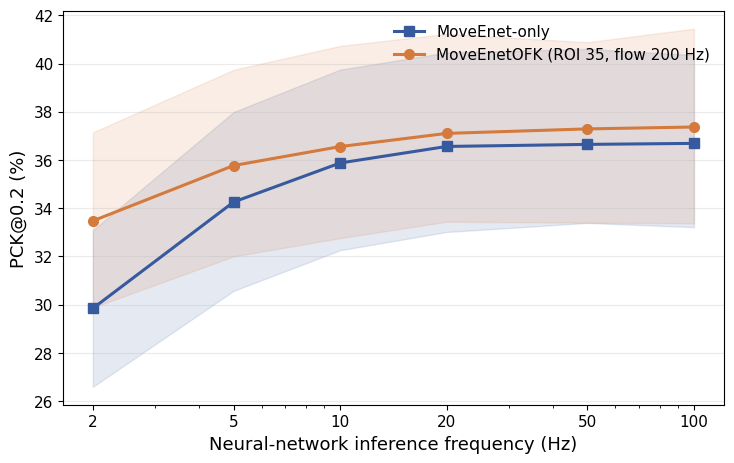

In [16]:
rates = sorted(summary.net_hz.unique())
fig, ax = plt.subplots(figsize=FIGSIZE)
for method in METHODS:
    group = summary[summary.method == method].set_index('net_hz').loc[rates]
    ax.plot(rates, group.pck02_percent,
            color=COLORS[method], marker=MARKERS[method], linewidth=LINE_WIDTH,
            markersize=MARKER_SIZE, label=LABELS[method])
    if SHOW_CI:
        ax.fill_between(rates, group.pck02_percent_ci_low,
                        group.pck02_percent_ci_high, color=COLORS[method], alpha=.13)
ax.set_xscale('log')
ax.set_xticks(rates, labels=[f'{x:g}' for x in rates])
ax.set_xlabel('Neural-network inference frequency (Hz)')
ax.set_ylabel('PCK@0.2 (%)')
ax.grid(axis='y', alpha=.25)
ax.legend(frameon=False)
fig.tight_layout()
if SAVE_FIGURES:
    for extension in FIGURE_FORMATS:
        fig.savefig(OUT / f'pck02_vs_network_rate.{extension}',
                    dpi=DPI, bbox_inches='tight')
plt.show()

## 9. Figure 2 — MPJPE vs neural-network inference frequency

Exported separately as an editable SVG and a PDF, plus a PNG.

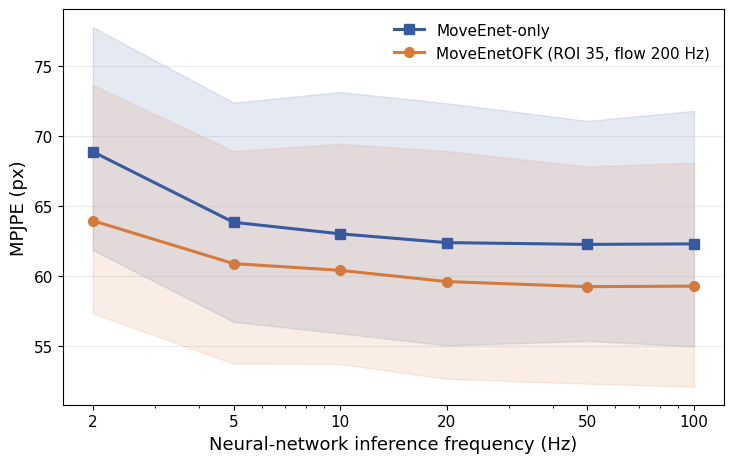

In [17]:
fig, ax = plt.subplots(figsize=FIGSIZE)
for method in METHODS:
    group = summary[summary.method == method].set_index('net_hz').loc[rates]
    ax.plot(rates, group.mpjpe_px,
            color=COLORS[method], marker=MARKERS[method], linewidth=LINE_WIDTH,
            markersize=MARKER_SIZE, label=LABELS[method])
    if SHOW_CI:
        ax.fill_between(rates, group.mpjpe_px_ci_low,
                        group.mpjpe_px_ci_high, color=COLORS[method], alpha=.13)
ax.set_xscale('log')
ax.set_xticks(rates, labels=[f'{x:g}' for x in rates])
ax.set_xlabel('Neural-network inference frequency (Hz)')
ax.set_ylabel('MPJPE (px)')
ax.grid(axis='y', alpha=.25)
ax.legend(frameon=False)
fig.tight_layout()
if SAVE_FIGURES:
    for extension in FIGURE_FORMATS:
        fig.savefig(OUT / f'mpjpe_vs_network_rate.{extension}',
                    dpi=DPI, bbox_inches='tight')
plt.show()

## 10. Per-joint MPJPE at 5 Hz (optional)

Uses the same joint mapping as the accuracy comparison. Large per-joint errors can reflect anatomical-marker differences, so treat this diagnostic cautiously.

method,"MoveEnetOFK (ROI 35, flow 200 Hz)",MoveEnet-only
joint,,
Head,68.24,71.37
Right shoulder,49.70,53.42
Left shoulder,51.53,55.19
Right elbow,59.16,62.76
Left elbow,61.09,64.83
Left hip,60.25,62.24
Right hip,55.52,57.83
Right wrist,88.32,92.30
Left wrist,82.39,86.31


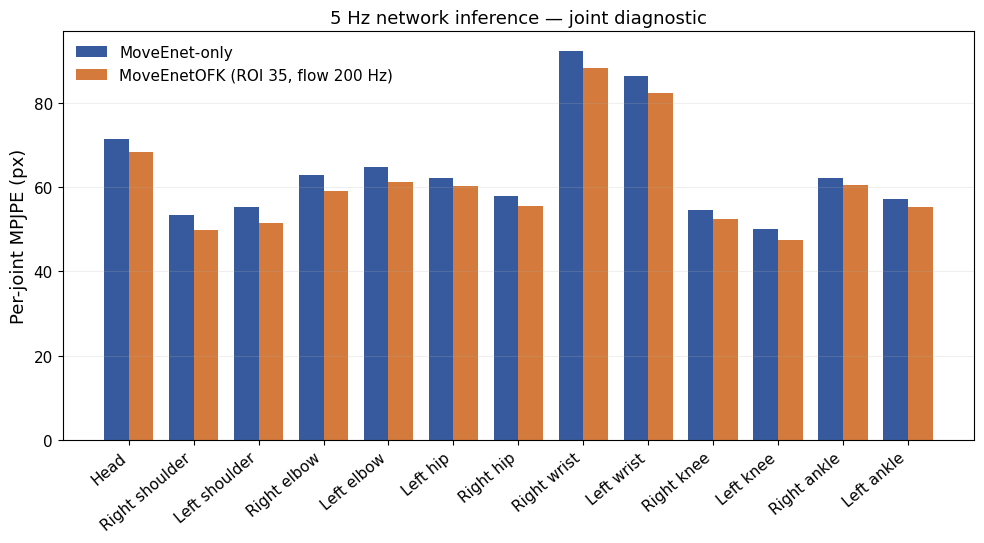

In [18]:
joint_5hz = joints[np.isclose(joints.net_hz, 5.0)].copy()
per_joint = joint_5hz.groupby(['joint', 'method'], as_index=False).agg(
    error_sum=('sum_error_px', 'sum'), joint_n=('valid_joints', 'sum'))
per_joint['mpjpe_px'] = per_joint.error_sum / per_joint.joint_n
joint_table = per_joint.pivot(index='joint', columns='method', values='mpjpe_px').reindex(JOINT_NAMES)
display(joint_table.rename(columns=LABELS).round(2))

fig, ax = plt.subplots(figsize=(10, 5.6))
x = np.arange(len(JOINT_NAMES))
width = .38
for offset, method in [(-.5, 'moveenet_only'), (.5, 'moveenet_ofk')]:
    ax.bar(x + offset*width, joint_table[method], width,
           color=COLORS[method], label=LABELS[method])
ax.set_xticks(x, JOINT_NAMES, rotation=40, ha='right')
ax.set_ylabel('Per-joint MPJPE (px)')
ax.set_title('5 Hz network inference — joint diagnostic')
ax.grid(axis='y', alpha=.2)
ax.legend(frameon=False)
fig.tight_layout()
if SAVE_FIGURES:
    for extension in FIGURE_FORMATS:
        fig.savefig(OUT / f'per_joint_mpjpe_5hz.{extension}', dpi=DPI, bbox_inches='tight')
plt.show()

## 11. Interpretation and protocol limits

This notebook requires only the **predictions and the existing 2D GT CSVs**; it does not load raw Vicon data.

The source GT is derived from motion-capture markers, not human-annotated 2D keypoints. Therefore the joint correspondence (especially elbow, wrist, hip, ankle markers) needs verification before final paper claims. The GT synchronization offset has not been independently verified. This is a limitation of the data, not an additional processing step.

In [19]:
print('Total samples analyzed:', len(manifest))
print('Total method/period runs:', len(samples))
print('Invalid (nonfinite) 2D GT joints:', int(gt_quality.gt_nonfinite_annotations.sum()))
print('Out-of-frame 2D GT joints:', int(gt_quality.gt_out_of_frame_annotations.sum()))
print('\nPaired OFK improvement (positive = better):')
print(deltas[['net_hz', 'pooled_mpjpe_reduction_px',
              'pooled_pck_improvement_pp']].to_string(index=False,
                                                      float_format=lambda x: f'{x:.3f}'))
print('\nExport directory:', OUT)
print('Reminder: 2D GT joint mapping and GT time offset remain provisional.')

Total samples analyzed: 59
Total method/period runs: 708
Invalid (nonfinite) 2D GT joints: 0
Out-of-frame 2D GT joints: 2678

Paired OFK improvement (positive = better):
 net_hz  pooled_mpjpe_reduction_px  pooled_pck_improvement_pp
  2.000                      4.938                      3.627
  5.000                      2.955                      1.512
 10.000                      2.614                      0.681
 20.000                      2.788                      0.541
 50.000                      3.022                      0.642
100.000                      3.025                      0.679

Export directory: /data/MoveEnet_OFK_results/Final_ROI_Gain1/Accuracy/moveiit/ExpA/analysis_2d_gt_expa_protocol
Reminder: 2D GT joint mapping and GT time offset remain provisional.
